In [33]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

In [34]:
image = Image.open('input_imgs/Lenna_(test_image).png').convert('L')

In [35]:
image_np = np.array(image)
image_np.shape

(512, 512)

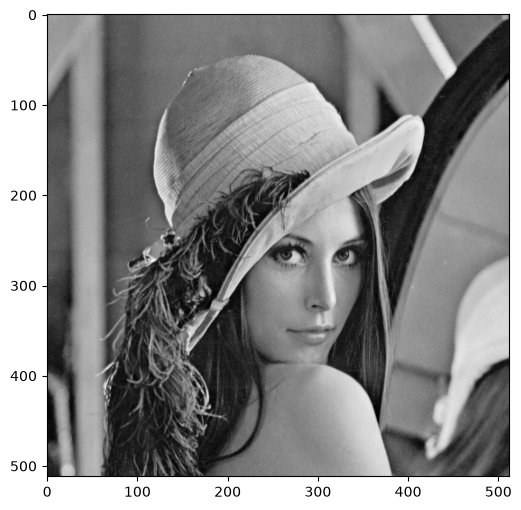

In [36]:
plt.figure(figsize=(6,6))
plt.imshow(image_np, cmap='gray')
plt.show()

## test for mean filter

In [37]:
test_img = np.array(
    [
        [1,2,3],
        [4,5,6],
        [7,8,9]
    ]
)

kernel_mean = np.array(
    [
        [1,1,1],
        [1,1,1],
        [1,1,1]
    ]
)

In [38]:
test_img_mean_result = (test_img * kernel_mean).sum() / kernel_mean.flatten().shape[0]
test_img_mean_result

np.float64(5.0)

In [39]:
def sliding_window(image, kernel):

    i_h, i_w = image.shape
    k_h, k_w = kernel.shape

    out_h = i_h - k_h + 1
    out_w = i_w - k_w + 1

    output = np.zeros((out_h, out_w))

    for i in range(out_h):
        for j in range(out_w):

            window = image[i:i+k_h, j:j+k_w]

            output[i,j] = np.sum(window * kernel) / kernel.sum()

    return output

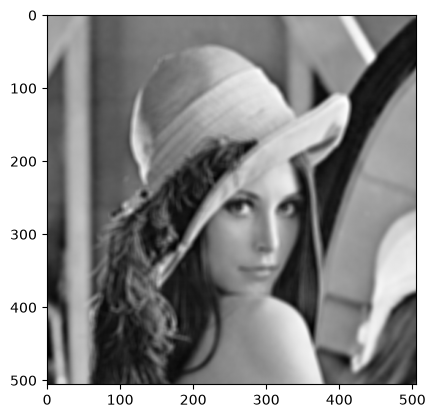

In [40]:
image_np_mean_3_3 = sliding_window(image_np, np.ones((7,7)))

plt.imshow(image_np_mean_3_3, cmap='gray')

Text(0.5, 1.0, '(482, 482)')

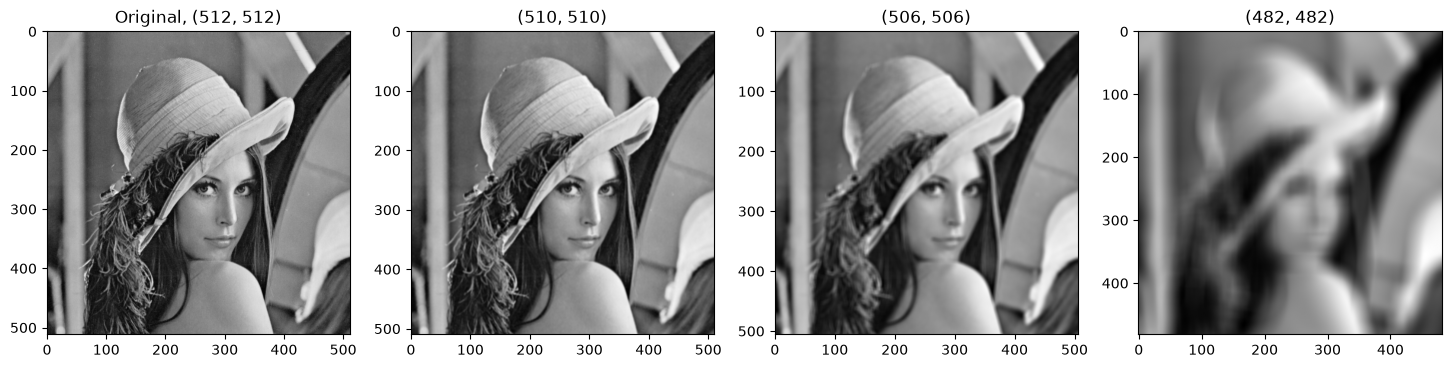

In [41]:
fig, axes = plt.subplots(1, 4, figsize=(18,10))

axes[0].imshow(image_np, cmap='gray')
axes[0].set_title(f'Original, {image_np.shape}')

res_3_3 = sliding_window(image_np, kernel_mean)
axes[1].imshow(res_3_3, cmap='gray')
axes[1].set_title(res_3_3.shape)

res_2 = sliding_window(image_np, np.ones((7,7)))
axes[2].imshow(res_2, cmap='gray')
axes[2].set_title(res_2.shape)

res_3 = sliding_window(image_np, np.ones((31,31)))
axes[3].imshow(res_3, cmap='gray')
axes[3].set_title(res_3.shape)

## sharp filtering

In [42]:
sharp_kernel_3_3 = np.array([
    [0, -1, 0],
    [-1, 5,-1],
    [0, -1, 0]
])

sharp_kernel_5_5 = np.array([
    [-1,-1,-1,-1,-1],
    [-1, 2, 2, 2,-1],
    [-1, 2, 8, 2,-1],
    [-1, 2, 2, 2,-1],
    [-1,-1,-1,-1,-1]
])

sharp_kernel_5_5_strong = np.array([
    [-1,-1,-1,-1,-1],
    [-1,-1,-1,-1,-1],
    [-1,-1,25,-1,-1],
    [-1,-1,-1,-1,-1],
    [-1,-1,-1,-1,-1]
])

Text(0.5, 1.0, '(508, 508)')

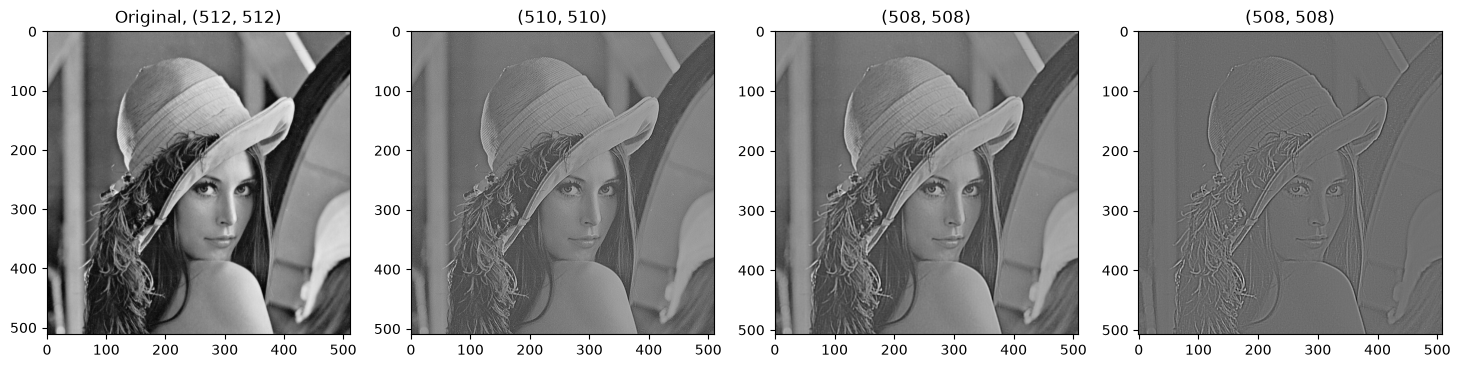

In [43]:
fig, axes = plt.subplots(1, 4, figsize=(18,10))

axes[0].imshow(image_np, cmap='gray')
axes[0].set_title(f'Original, {image_np.shape}')

sharp_res_3_3 = sliding_window(image_np, sharp_kernel_3_3)
axes[1].imshow(sharp_res_3_3, cmap='gray')
axes[1].set_title(sharp_res_3_3.shape)

sharp_res_2 = sliding_window(image_np, sharp_kernel_5_5)
axes[2].imshow(sharp_res_2, cmap='gray')
axes[2].set_title(sharp_res_2.shape)

sharp_res_3 = sliding_window(image_np, sharp_kernel_5_5_strong)
axes[3].imshow(sharp_res_3, cmap='gray')
axes[3].set_title(sharp_res_3.shape)